In [ ]:
# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Set visualization aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11

In [ ]:
# Step 2: Loading Dataset

df = pd.read_csv('/content/3rd_DS_Placement.csv')
df.head(10)

,accX,accY,accZ,gyroX,gyroY,gyroZ,timestamp,Activity
0,-0.496517,3.785628,8.954828,-0.142849,-0.126159,-0.022539,34:22.9,1
1,-0.462388,3.869603,9.281898,0.084349,0.096695,0.092130,34:23.0,1
2,-0.296084,3.820505,8.930728,0.061763,0.051543,0.071287,34:23.1,1
3,-0.469723,3.890110,8.744067,0.007641,0.028679,0.109433,34:23.2,1
4,-0.472418,4.109105,8.941207,-0.123640,0.099057,0.051943,34:23.3,1
5,-0.837359,4.051176,8.473878,0.031954,-0.039420,0.144715,34:23.4,1
6,-1.093476,4.698280,8.900940,-0.291323,0.145343,-0.033145,34:23.5,1
7,-1.131347,4.305197,8.348439,-0.136222,0.024592,0.256020,34:23.6,1
8,-0.628693,4.660259,8.403974,-0.106731,0.015743,0.084673,34:23.7,1
9,-0.941392,4.661007,8.276888,0.083646,0.004052,0.138814,34:23.8,1


In [ ]:
# No Missing Values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31991 entries, 0 to 31990
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   accX       31991 non-null  float64
 1   accY       31991 non-null  float64
 2   accZ       31991 non-null  float64
 3   gyroX      31991 non-null  float64
 4   gyroY      31991 non-null  float64
 5   gyroZ      31991 non-null  float64
 6   timestamp  31991 non-null  object 
 7   Activity   31991 non-null  int64  
dtypes: float64(6), int64(1), object(1)
memory usage: 2.0+ MB


In [ ]:
df.describe(include='all')

,accX,accY,accZ,gyroX,gyroY,gyroZ,timestamp,Activity
count,31991.000000,31991.000000,31991.000000,31991.000000,31991.000000,31991.000000,31991,31991.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,21776,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,59:21.3,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN
mean,0.023825,2.153858,9.537909,-0.004493,-0.014756,-0.007021,NaN,0.982151
std,0.741396,1.085466,2.056358,0.307643,0.249201,0.266120,NaN,0.132404
min,-3.673361,-4.386029,4.296066,-1.470421,-1.430659,-1.894102,NaN,0.000000
25%,-0.472193,1.413062,7.794217,-0.149783,-0.162656,-0.154126,NaN,1.000000
50%,-0.024998,2.119143,9.406739,0.022301,-0.011060,0.005261,NaN,1.000000
75%,0.477208,2.928435,11.158845,0.177978,0.124966,0.152061,NaN,1.000000


=== Dataset Overview ===
Shape: 31991 rows, 8 columns
Found 1 row(s) with a bad timestamp format:
           accX      accY      accZ     gyroX     gyroY     gyroZ  \
20928 -0.411345  0.726589  9.846674  0.010058  0.005086  0.012459   

             timestamp  Activity  
20928  6/25/2022 14:05         0  
After dropping duplicates, shape: 31846 rows, 9 columns
Recordings: 91
Recordings containing class 0: 1


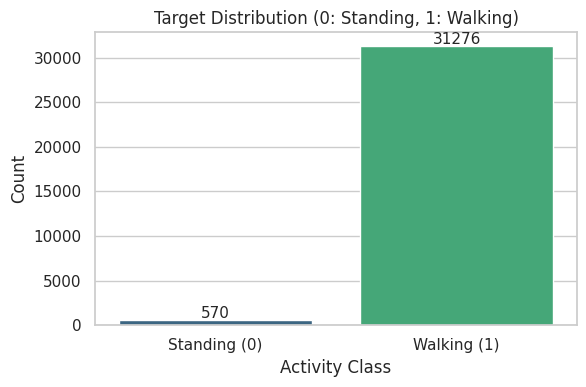

In [ ]:
# Step 3: Drop Duplicates & Data Exploration

print("=== Dataset Overview ===")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")

ts = df['timestamp'].str.extract(r'^(\d+):(\d+\.\d+)$')
bad = ts[0].isna()
print(f"Found {bad.sum()} row(s) with a bad timestamp format:")
print(df[bad])

df = df[~bad].copy(); ts = ts[~bad]
df['sec'] = ts[0].astype(float) * 60 + ts[1].astype(float)

# Drop duplicate records if present
df.drop_duplicates(inplace=True)
print(f"After dropping duplicates, shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.reset_index(drop=True, inplace=True)

gap = (df['sec'].diff() + 1800) % 3600 - 1800
new_rec = gap.abs() > 1.0
new_rec.iloc[0] = True
df['recording'] = new_rec.cumsum()
print("Recordings:", df['recording'].nunique())
print("Recordings containing class 0:", df.loc[df.Activity == 0, 'recording'].nunique())

# Target class distribution plot
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Activity', data=df, palette='viridis')
ax.set_xticklabels(['Standing (0)', 'Walking (1)'])
plt.title('Target Distribution (0: Standing, 1: Walking)')
plt.xlabel('Activity Class')
plt.ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.show()

In [ ]:
# Step 4. Feature Engineering

# 4.1 Calculate Vector Magnitudes
df['acc_mag'] = np.sqrt(df['accX']**2 + df['accY']**2 + df['accZ']**2)
df['gyro_mag'] = np.sqrt(df['gyroX']**2 + df['gyroY']**2 + df['gyroZ']**2)

# 4.2 Extract Rolling Window Statistics (Window Size = 10)
window_size = 10
sensor_cols = ['accX', 'accY', 'accZ', 'gyroX', 'gyroY', 'gyroZ', 'acc_mag', 'gyro_mag']

feats = {}
for c in sensor_cols:
    r = df.groupby('recording')[c].rolling(window_size, min_periods=window_size // 2)
    feats[f'{c}_roll_std'] = r.std().reset_index(level=0, drop=True)
    feats[f'{c}_roll_rng'] = (r.max() - r.min()).reset_index(level=0, drop=True)

    if c.endswith('_mag'):
      feats[f'{c}_roll_mean'] = r.mean().reset_index(level=0, drop=True)

X = pd.DataFrame(feats).loc[df.index]
keep = X.notna().all(axis=1)
X, y, meta = X[keep], df.loc[keep, 'Activity'], df.loc[keep]
print(f"X Shape: {X.shape[0]} rows, {X.shape[1]} columns")
print(f"y Shape: {y.shape[0]} rows")
print(f"meta Shape: {meta.shape[0]} rows, {meta.shape[1]} columns")

X Shape: 31482 rows, 18 columns
y Shape: 31482 rows
meta Shape: 31482 rows, 12 columns


In [ ]:
# Step 5. Train-Test Split

label_run = (meta['Activity'] != meta['Activity'].shift()) | (meta['recording'] != meta['recording'].shift())
run_id = label_run.cumsum()
groups = run_id.astype(str) + '_' + (meta.groupby(run_id).cumcount() // 300).astype(str)

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
folds = list(cv.split(X, y, groups))
print("Class-0 rows in each test fold:", [int((y.iloc[te] == 0).sum()) for _, te in folds])

Class-0 rows in each test fold: [290, 127, 149]


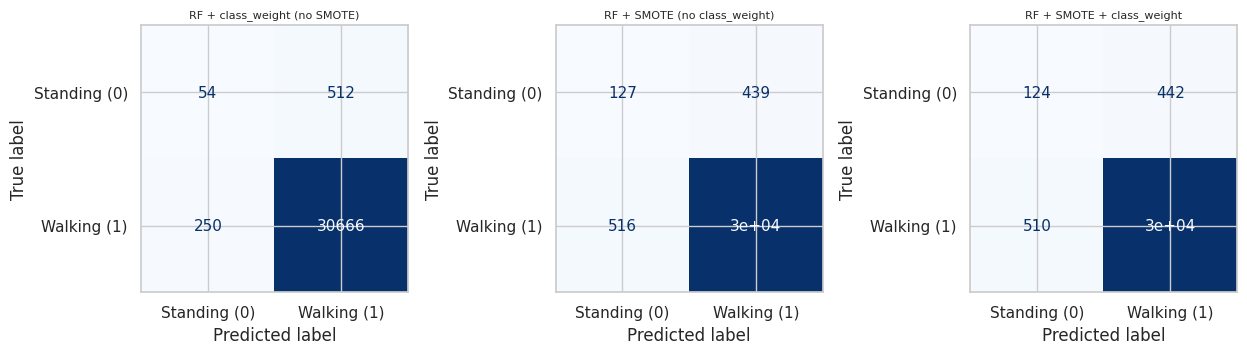

=== SMOTE vs class_weight vs both (grouped CV, class 0 = standing) ===
                       Model  Accuracy  F1 (macro avg)  Prec (standing)  Rec (standing)  F1 (standing)  ROC-AUC
RF + SMOTE (no class_weight)     0.970           0.597            0.198           0.224          0.210    0.835
   RF + SMOTE + class_weight     0.970           0.596            0.196           0.219          0.207    0.813
RF + class_weight (no SMOTE)     0.976           0.556            0.178           0.095          0.124    0.803


In [ ]:
# Step 6: Model Training & Evaluation (SMOTE vs class_weight vs both)

MINORITY = 0
candidates = {
    'RF + class_weight (no SMOTE)': RandomForestClassifier(
        class_weight='balanced_subsample', n_jobs=-1, random_state=42),

    'RF + SMOTE (no class_weight)': ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf', RandomForestClassifier(n_jobs=-1, random_state=42))
    ]),

    'RF + SMOTE + class_weight': ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf', RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=42))
    ]),
}

def scores(yt, yp, p0):
    return {
        'Accuracy': accuracy_score(yt, yp),
        'F1 (macro avg)': f1_score(yt, yp, average='macro'),
        'Prec (standing)': precision_score(yt, yp, pos_label=0, zero_division=0),
        'Rec (standing)': recall_score(yt, yp, pos_label=0),
        'F1 (standing)': f1_score(yt, yp, pos_label=0),
        'ROC-AUC': roc_auc_score(yt == 0, p0),
    }

rows, oof = [], {}
for name, values in candidates.items():
    pred = pd.Series(0, index=X.index)
    prob = pd.Series(0.0, index=X.index)

    for tr, te in folds:
        X_train, y_train = X.iloc[tr], y.iloc[tr]  # training data for the round
        X_test = X.iloc[te]                        # test data for the round

        m = clone(values).fit(X_train, y_train)        # train fresh model on round's training data
        pred.iloc[te] = m.predict(X_test)            # predict on round's test data
        prob.iloc[te] = m.predict_proba(X_test)[:, list(m.classes_).index(MINORITY)]

    oof[name] = (pred, prob)
    rows.append({'Model': name, **scores(y, pred, prob)})   # compare predictions to the REAL y at the end

fig, axes = plt.subplots(1, len(oof), figsize=(4.2 * len(oof), 4))
for ax, (name, (p, _)) in zip(axes, oof.items()):
    ConfusionMatrixDisplay(confusion_matrix(y, p, labels=[0, 1]),
        display_labels=['Standing (0)', 'Walking (1)']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name, fontsize=8)
plt.tight_layout()
plt.show()

results_df = pd.DataFrame(rows).sort_values(by='F1 (standing)', ascending=False)
print("=== SMOTE vs class_weight vs both (grouped CV, class 0 = standing) ===")
print(results_df.round(3).to_string(index=False))

Winning strategy from previous cell: RF + SMOTE (no class_weight)


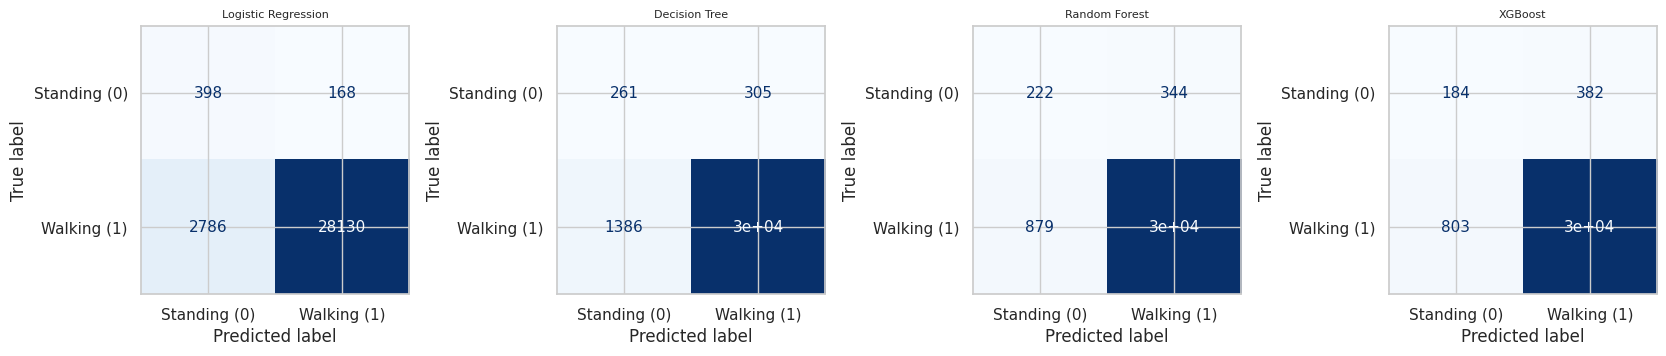

=== Model comparison, all using SMOTE (winning strategy) ===
              Model  Accuracy  F1 (macro avg)  Prec (standing)  Rec (standing)  F1 (standing)  ROC-AUC
      Random Forest     0.961           0.623            0.202           0.392          0.266    0.844
            XGBoost     0.962           0.609            0.186           0.325          0.237    0.842
      Decision Tree     0.946           0.604            0.158           0.461          0.236    0.713
Logistic Regression     0.906           0.581            0.125           0.703          0.212    0.833


In [ ]:
# Step 7: Model Comparison using the winning strategy (SMOTE, no class_weight)

winning_strategy = results_df.iloc[0]['Model']
print("Winning strategy from previous cell:", winning_strategy)

base_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, eval_metric='logloss', random_state=42),
}

# winning_strategy = 'SMOTE (no class_weight)' -> applying it to every model
candidates2 = {
    name: ImbPipeline([('smote', SMOTE(random_state=42)), ('clf', model)])
    for name, model in base_models.items()
}

rows2, oof2 = [], {}
for name, values in candidates2.items():
    pred = pd.Series(0, index=X.index)
    prob = pd.Series(0.0, index=X.index)

    for tr, te in folds:
        m = clone(values).fit(X.iloc[tr], y.iloc[tr])
        pred.iloc[te] = m.predict(X.iloc[te])
        prob.iloc[te] = m.predict_proba(X.iloc[te])[:, list(m.classes_).index(MINORITY)]

    oof2[name] = (pred, prob)
    rows2.append({'Model': name, **scores(y, pred, prob)})

fig, axes = plt.subplots(1, len(oof2), figsize=(4.2 * len(oof2), 4))
for ax, (name, (p, _)) in zip(axes, oof2.items()):
    ConfusionMatrixDisplay(confusion_matrix(y, p, labels=[0, 1]),
        display_labels=['Standing (0)', 'Walking (1)']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name, fontsize=8)
plt.tight_layout()
plt.show()

results_df2 = pd.DataFrame(rows2).sort_values(by='F1 (standing)', ascending=False)
print("=== Model comparison, all using SMOTE (winning strategy) ===")
print(results_df2.round(3).to_string(index=False))

In [ ]:
# Step 8: Final Model: Full Classification Report

final_model_name = results_df2.iloc[0]['Model']
final_pred = oof2[final_model_name][0]
print(f"Final model: {final_model_name}\n")
print(classification_report(y, final_pred, target_names=['Standing (0)', 'Walking (1)'], digits=3))

Final model: Random Forest

              precision    recall  f1-score   support

Standing (0)      0.202     0.392     0.266       566
 Walking (1)      0.989     0.972     0.980     30916

    accuracy                          0.961     31482
   macro avg      0.595     0.682     0.623     31482
weighted avg      0.975     0.961     0.967     31482



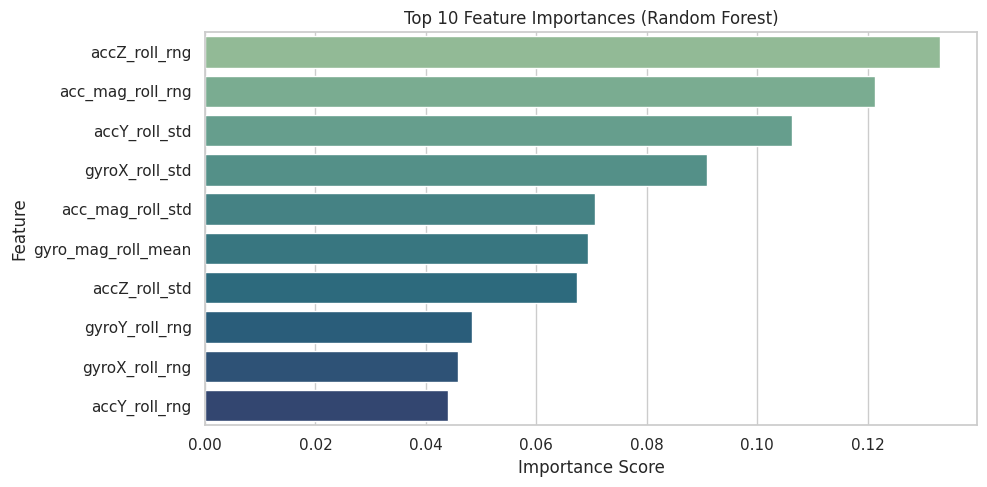

In [ ]:
# Step 9: Feature Importance Analysis (final model, refit on all data)

best_est = clone(candidates2[final_model_name]).fit(X, y)
best_model = best_est.named_steps['clf'] if hasattr(best_est, 'named_steps') else best_est

if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
elif hasattr(best_model, 'coef_'):
    importances = np.abs(best_model[-1].coef_[0]) if hasattr(best_model, '__getitem__') else np.abs(best_model.coef_[0])
else:
    raise ValueError(f"{final_model_name} has neither feature_importances_ nor coef_")

feat_imp_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='crest')
plt.title(f'Top 10 Feature Importances ({final_model_name})')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()